## Predicting Medical Expenses for an Insurance Company Using Multiple Linear Regression

### **Introduction:** 
In this activity, we will explore the concept of linear regression using the `insurance.csv` dataset. Linear regression is a supervised learning technique used to predict the value of a dependent variable (in this case, `charges`, based on one or more independent variables (for example, `age`, `bmi`, `children`, etc.).

You can download the dataset from [here](https://www.kaggle.com/datasets/mirichoi0218/insurance?resource=download).

The `insurance.csv` dataset contains information about individuals and their medical charges. Each of the variables in the file is described below:

1. **age**: The individual's age (in years).
2. **sex**: The individual's sex (male for men and female for women).
3. **bmi**: The individual's Body Mass Index (BMI), a measure of weight relative to height.
4. **children**: Number of children or dependents the individual has.
5. **smoker**: Indicates whether the individual is a smoker (yes or no).
6. **region**: Geographic region where the individual resides (northeast, northwest, southeast, southwest).
7. **charges**: Total medical charges billed to the individual (in dollars).

These variables are commonly used to analyze and predict medical costs based on individuals' demographic and health characteristics.


### **Contents:**

#### Import the required packages

In [31]:
# Install the required packages
%pip install scikit-learn # Machine learning package with classification, regression, clustering algorithms, etc.
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install numpy

# Import the required packages
from sklearn.linear_model import LinearRegression # Linear regression with scikit-learn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip




#### Load the dataset



In [32]:
# Load the dataset directly from the GitHub repository
insurance = pd.read_csv('https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/insurance.csv')
insurance.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [33]:
# Print the unique values of 'region' 
insurance['region'].unique()

array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

#### Data preprocessing

#### Why use dummy variables for region instead of a numeric mapping?

Linear regression needs numeric inputs, but converting a category to a number also introduces assumptions. `region` is **nominal**: northeast, northwest, southeast, and southwest have no natural ranking.

| Encoding | Advantages | Disadvantages |
|---|---|---|
| Map regions to 0, 1, 2, 3 | Short code and only one column | Imposes an artificial order and equal spacing. One coefficient forces the same change in predicted charges between consecutive codes; changing the assigned numbers can change the fitted predictions. |
| Dummy variables (one-hot encoding) | Represents each region with a separate binary indicator without assuming an order | Adds columns and requires consistent encoding when predicting new cases. Many categories can create a large feature matrix. |

For example, mapping northeast → 0, northwest → 1, southeast → 2, and southwest → 3 would force the southwest-versus-northeast contribution to be three times the northwest-versus-northeast contribution. There is no reason to impose that relationship.

For this explanation exercise, we keep **all four region columns** with `drop_first=False`, so every region appears in the coefficient and contribution plots. Each record has exactly one active region indicator. No region is omitted or used as a reference category: `northeast`, `northwest`, `southeast`, and `southwest` each have their own column.

With an intercept, these four columns are redundant: their sum is always one. The individual region coefficients and intercept are therefore not uniquely identifiable. The least-squares solver selects a numerical solution; different coefficient representations can give the same predictions on valid records. Keeping all regions does not force coefficient signs to match SHAP signs. To compare two regions while holding the other predictors fixed, subtract their fitted coefficients.

Mapping works well for the binary features here: `smoker` and `sex` have only two categories, so their single coefficient represents a difference between two groups. For a genuinely ordered feature, numeric mapping may be reasonable, but a linear model still assumes equal effects per code step. For `region`, dummy encoding is the clearer choice.

In [34]:
# Encode the categorical variables 'sex' and 'smoker' by replacing labels (label encoding)
insurance['sex'] = insurance['sex'].replace({'female': 0, 'male': 1})
insurance['smoker'] = insurance['smoker'].replace({'no': 0, 'yes': 1})

# Keep all four region indicators visible for the explanation exercise
insurance = pd.get_dummies(insurance, columns=['region'], drop_first=False, dtype=int)

# Display the first 10 rows after preprocessing
insurance.head(10)

C:\Users\pauls\AppData\Local\Temp\ipykernel_13476\643149133.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  insurance['sex'] = insurance['sex'].replace({'female': 0, 'male': 1})
C:\Users\pauls\AppData\Local\Temp\ipykernel_13476\643149133.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  insurance['smoker'] = insurance['smoker'].replace({'no': 0, 'yes': 1})


,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,0,1
1,18,1,33.770,1,0,1725.55230,0,0,1,0
2,28,1,33.000,3,0,4449.46200,0,0,1,0
3,33,1,22.705,0,0,21984.47061,0,1,0,0
4,32,1,28.880,0,0,3866.85520,0,1,0,0
5,31,0,25.740,0,0,3756.62160,0,0,1,0
6,46,0,33.440,1,0,8240.58960,0,0,1,0
7,37,0,27.740,3,0,7281.50560,0,1,0,0
8,37,1,29.830,2,0,6406.41070,1,0,0,0
9,60,0,25.840,0,0,28923.13692,0,1,0,0


#### Prepare the variables `X` and `y`

In [35]:
# Select the independent variables (X)
X = insurance.drop('charges', axis=1)
X

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,0,0,0,1
1,18,1,33.770,1,0,0,0,1,0
2,28,1,33.000,3,0,0,0,1,0
3,33,1,22.705,0,0,0,1,0,0
4,32,1,28.880,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,0,1,0,0
1334,18,0,31.920,0,0,1,0,0,0
1335,18,0,36.850,0,0,0,0,1,0
1336,21,0,25.800,0,0,0,0,0,1


In [36]:
# Select the dependent variable (y)
y = insurance['charges']
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64

#### Split the data into training and test sets

In [37]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### Instantiate a Linear Regression model and fit it with the values of `X_train` and `y_train`

In [38]:
# Create an instance of the linear regression model
regression_model = LinearRegression()

# Fit the model to the training data
regression_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


##### **(Optional)** Save the model in .pkl format

The `.pkl` format is a file extension used to store serialized objects in Python through the `pickle` module. This module allows Python objects to be converted into a sequence of bytes, making it easier to store them in files or transmit them over networks. `.pkl` files are commonly used to save trained machine learning models, complex data structures, or any other object that needs to persist between program execution sessions. Deserializing these files allows objects to be restored to their original state, keeping their structure and data intact.

In [39]:
# Save the model for future use
import joblib
joblib.dump(regression_model, 'regression_model.pkl')

['regression_model.pkl']

##### **(Optional)** Load the model in .pkl format

In [40]:
# Load the saved model
regression_model = joblib.load('regression_model.pkl')

#### Get the coefficients and intercept of the regression model

In the context of linear regression, the coefficients and intercept are fundamental parameters that define the relationship between the independent (predictor) variables and the dependent (response) variable.

##### *a) Coefficients*
The coefficients (also known as weights or betas) represent the magnitude and direction of the relationship between each independent variable and the dependent variable. In a multiple linear regression equation, each coefficient indicates how much the dependent variable changes when the corresponding independent variable increases by one unit, holding the other independent variables constant. Mathematically, if we have a linear regression equation of the form:

$y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \ldots + \beta_n X_n$

where:
- $y$ is the dependent (target) variable.
- $\beta_0$ is the intercept.
- $\beta_1, \beta_2, \ldots, \beta_n $ are the coefficients of the independent variables $X_1, X_2, \ldots, X_n$.

##### *b) Intercept*
The intercept $\beta_0$ is the value of the dependent variable when all the independent variables are equal to zero. It represents the point where the regression line crosses the $y$ axis. In other words, it is the predicted value of $y$ when there is no influence from the independent variables.

##### Example:
If we have a multiple linear regression equation with two independent variables, it could look like this:

$y = 3 + 2X_1 - 4X_2$

In this case:
- The intercept $\beta_0$ is 3.
- The coefficient of $X_1$ ($\beta_1$) is 2, which means that for each one-unit increase in $X_1$, $y$ increases by 2 units.
- The coefficient of $X_2$ ($\beta_2$) is -4, which means that for each one-unit increase in $X_2$, $y$ decreases by 4 units.

These parameters are essential for interpreting the linear regression model and understanding how the independent variables affect the dependent variable.

In [41]:
# Get the coefficients 
coefficients = regression_model.coef_
coefficients

array([ 2.56975706e+02, -1.85916916e+01,  3.37092552e+02,  4.25278784e+02,
        2.36511289e+04,  4.59585244e+02,  8.89079180e+01, -1.98279052e+02,
       -3.50214110e+02])

In [42]:
# Get the intercept 
intercept = regression_model.intercept_
intercept

np.float64(-12390.804294570278)

In [43]:
# Define the regression line equation
line_equation = 'y = ' + ' + '.join([f'{coefficients[i]}*X{i}' for i in range(len(coefficients))]) + f' + {intercept}'
print(f'Regression line equation: {line_equation}')

Regression line equation: y = 256.97570583119455*X0 + -18.591691641004672*X1 + 337.09255194877466*X2 + 425.27878352427877*X3 + 23651.128855761235*X4 + 459.5852442437305*X5 + 88.90791801592536*X6 + -198.279052320906*X7 + -350.2141099387532*X8 + -12390.804294570278


With the regression line equation, we can make predictions about medical charges based on the input features. This equation allows us to understand how each feature influences the final outcome, providing a clear mathematical relationship between the independent variables (features) and the dependent variable (medical charges). By applying this equation to new data, we can estimate the expected medical charges, which is useful for predictive analysis, informed decision-making, and resource planning in healthcare. In addition, the regression line equation makes it easier to interpret the coefficients, helping us identify which factors have the greatest impact on medical costs.

The coefficients represent the expected change in medical charges for a one-unit increase in the corresponding independent variable, holding the other variables constant.

Their interpretation depends on the variable's units and encoding:

1. **Numerical variables**: A coefficient describes the change in predicted charges per unit of the variable. Raw coefficient magnitudes cannot be compared directly across variables measured on different scales.
2. **Binary variables**: A coefficient describes the difference in predicted charges between the category coded as 1 and the category coded as 0, holding the other variables constant. For region, all four indicators are included. Switching from region A to region B changes two indicators, so the predicted difference is the coefficient of B minus the coefficient of A. A single region coefficient is not a uniquely identified effect because the model also has an intercept.

The sign indicates the direction of the fitted association:

- **Positive coefficient**: A higher value is associated with higher predicted medical charges.
- **Negative coefficient**: A higher value is associated with lower predicted medical charges.

Standardizing the predictors makes coefficient magnitudes more comparable in terms of a one-standard-deviation change. However, correlated predictors can make coefficients unstable, and coefficient magnitude alone does not establish predictive importance, statistical significance, or causality.

In [44]:
# Create a DataFrame to make interpretation easier
coef_df = pd.DataFrame({'Variable': X.columns, 'Coefficient': coefficients})

# Sort by absolute coefficient magnitude; the predictors have different units
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()

# Sort the coefficients from highest to lowest
coef_df = coef_df.sort_values(by='Abs_Coefficient', ascending=False)

print(coef_df)

           Variable   Coefficient  Abs_Coefficient
4            smoker  23651.128856     23651.128856
5  region_northeast    459.585244       459.585244
3          children    425.278784       425.278784
8  region_southwest   -350.214110       350.214110
2               bmi    337.092552       337.092552
0               age    256.975706       256.975706
7  region_southeast   -198.279052       198.279052
6  region_northwest     88.907918        88.907918
1               sex    -18.591692        18.591692


C:\Users\pauls\AppData\Local\Temp\ipykernel_13476\1143019381.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Variable', data=coef_df, palette='coolwarm')


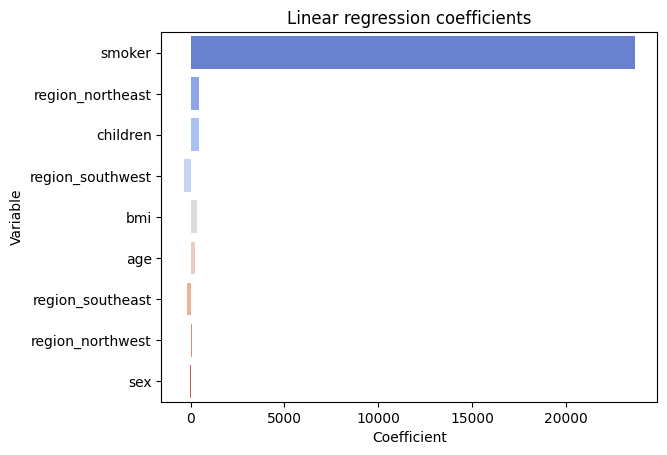

In [45]:
# Plot the coefficients sorted from highest to lowest in a bar chart
sns.barplot(x='Coefficient', y='Variable', data=coef_df, palette='coolwarm')

plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.title('Linear regression coefficients')
plt.show()

#### Do smaller coefficients mean that age and BMI are unimportant?

No. The model uses both variables, but the raw coefficient chart compares different units:

- The `age` coefficient is the predicted change in dollars for **one additional year**, holding the other predictors fixed.
- The `bmi` coefficient is the predicted change in dollars for **one BMI unit**, holding the other predictors fixed.
- The `smoker` coefficient represents the **entire change from nonsmoker (0) to smoker (1)**.

A one-year change is not directly comparable to a change in smoking status. Across ten years, the fitted age contribution changes by $10\beta_{\mathrm{age}}$; across five BMI units, it changes by $5\beta_{\mathrm{bmi}}$. Thus, relatively small per-unit coefficients can accumulate into substantial differences across the observed feature range.

A large smoking coefficient can also visually compress the other bars. The standardized-coefficient section below compares changes of one standard deviation, and the final SHAP section compares contributions in dollars across the test observations.

This additive model also assigns one constant slope to age and one to BMI. It does not include nonlinear effects or a BMI-by-smoking interaction. If those relationships matter, the current model may miss them; a small coefficient is not evidence that the feature has no predictive value. Neither coefficients nor SHAP values establish a causal health effect.

#### Calculate the model evaluation metrics (making predictions on the test set)

In the context of linear regression, it is essential to evaluate the model's performance to understand its accuracy and generalization ability. There are several evaluation metrics that help us quantify the error and quality of the model's predictions. Among the most common are:

1. **Mean Squared Error (MSE)**: This metric calculates the average of the squared errors, that is, the difference between the predicted values $\hat{y}_i$ and the actual values $y_i$. MSE heavily penalizes large errors due to squaring, making it a metric that is sensitive to outliers. A lower MSE indicates a better fit of the model to the data. The MSE formula is:
   
   $\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$
   
   where $n$ is the number of observations.

2. **R-squared (R²)**: Also known as the coefficient of determination, this metric indicates the proportion of the variance in the dependent variable that is explained by the model's independent variables. For a nonconstant target, $R^2$ has a maximum of $1$ and can be negative. A value of $1$ indicates perfect predictions, while $0$ corresponds to predicting the mean of the target values in the evaluation set. A negative value means that the predictions are worse than that mean-based reference. This reference is distinct from the training-mean baseline evaluated below. The $R^2$ formula is:
   
   $R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$
   
   where $\bar{y}$ is the mean of the actual values $y_i$.

3. **Mean Absolute Error (MAE)**: This metric calculates the average of the absolute errors, that is, the absolute difference between the predicted values $\hat{y}_i$ and the actual values $y_i$. Unlike MSE, MAE does not penalize large errors as much, making it more robust to outliers. A lower MAE indicates better model performance. The MAE formula is:
   
   $\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$
   
   where $n$ is the number of observations.

These metrics provide different perspectives on model performance and, when used together, can provide a more complete and robust evaluation of the quality of the linear regression model's predictions.

In [46]:
# Make predictions on the test set
y_pred = regression_model.predict(X_test)

# Import the metrics to evaluate the model
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Calculate the evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Print the evaluation metrics
print(f'Mean Squared Error (MSE): {mse}')
print(f'Coefficient of Determination (R^2): {r2}')
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Root Mean Squared Error (RMSE): {rmse}')

Mean Squared Error (MSE): 33596915.85136146
Coefficient of Determination (R^2): 0.7835929767120723
Mean Absolute Error (MAE): 4181.194473753641
Root Mean Squared Error (RMSE): 5796.2846592762735


#### Compare against a mean-prediction baseline

A baseline predicts the mean medical charge from the training set for every test case. Compare both models on the same test set: lower MAE and RMSE indicate smaller errors, measured in dollars. The training mean is used to avoid learning from the test targets.

In [47]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy='mean')
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

comparison = pd.DataFrame({
    'Model': ['Training mean baseline', 'Linear regression'],
    'MAE ($)': [mean_absolute_error(y_test, y_pred_baseline), mae],
    'RMSE ($)': [np.sqrt(mean_squared_error(y_test, y_pred_baseline)), rmse],
    'R²': [r2_score(y_test, y_pred_baseline), r2]
})
print(comparison.to_string(index=False))

                 Model     MAE ($)     RMSE ($)        R²
Training mean baseline 9593.338461 12465.610442 -0.000919
     Linear regression 4181.194474  5796.284659  0.783593


#### Inspect the residuals

A residual is the actual charge minus the predicted charge. Positive residuals indicate underestimation; negative residuals indicate overestimation. Look for residuals scattered around zero. Curves or distinct groups may suggest relationships the model misses, while a widening spread may indicate that error variability changes with predicted charges.

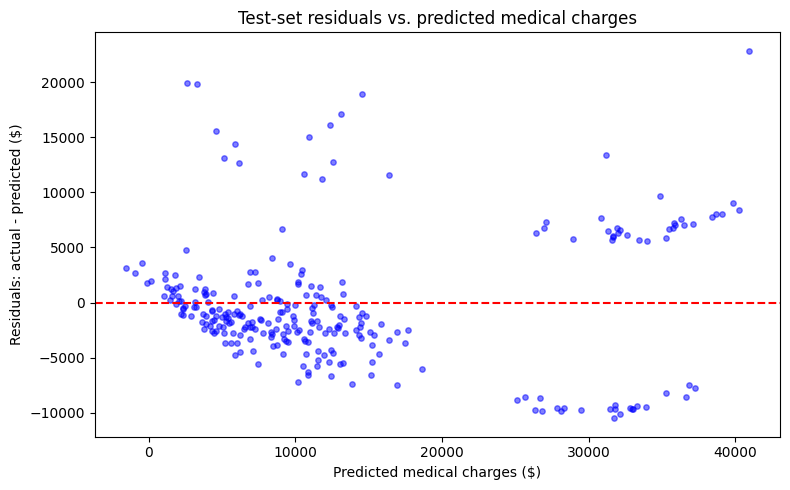

In [48]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, color='blue', alpha=0.5, s=15)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted medical charges ($)')
plt.ylabel('Residuals: actual - predicted ($)')
plt.title('Test-set residuals vs. predicted medical charges')
plt.tight_layout()
plt.show()

#### Make predictions for a new insurance company customer

In [49]:
# Define a new test case with the following values
new_case = pd.DataFrame({
    'age': [30],  # Age
    'sex': [1],  # Gender (0: female, 1: male)
    'bmi': [19],  # Body mass index
    'children': [1],  # Number of children
    'smoker': [0],  # Smoker (0: no, 1: yes)
    'region_northeast': [0],  # Northeast region
    'region_northwest': [1],  # Northwest region
    'region_southeast': [0],  # Southeast region
    'region_southwest': [0]  # Southwest region
})

# Make the prediction with the new test case
prediction = regression_model.predict(new_case)

# Print the prediction result
print(f'The estimated cost of medical insurance is: ${prediction[0]:.2f}')

The estimated cost of medical insurance is: $2218.82


In the case of multiple regression, where you have more than one independent variable, the relationship between the independent variables and the dependent variable is represented in a **higher-dimensional space**. Therefore, instead of a regression line (which applies to simple regression with a single independent variable), you would have a hyperplane in a multidimensional space.

However, you can visualize the relationship between the actual values and the predicted values in a scatter plot, as shown below. This type of plot is useful for evaluating the accuracy of the model's predictions.

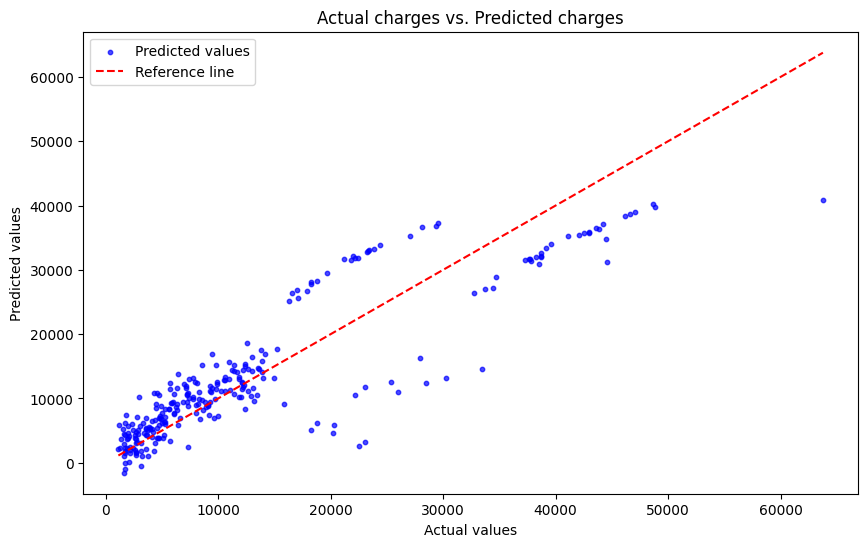

In [50]:
# Plot the actual values vs the predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7, s=10)
plt.title('Actual charges vs. Predicted charges')
plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')  # Reference line
plt.legend(['Predicted values', 'Reference line'])
plt.show()

In this plot:
- The blue points represent the actual values against the predicted values.
- The dashed red line is a reference line that indicates where the points would be if the predictions were perfect (that is, $y_{\text{actual}} = y_{\text{predicted}}$).

This plot allows you to visualize how close the predictions are to the actual values. If the predictions are perfect, all the points will fall on the reference line.

**Note:** Negative predicted values can occur because ordinary linear regression does not constrain its predictions. Negative medical charges have no practical meaning.

Possible approaches include:

1. **Target transformation**: Consider fitting the model to `log1p(charges)` and converting predictions back with `expm1`. Evaluate performance in dollars after the inverse transformation; this changes the fitting objective and may introduce retransformation bias. Standardizing the predictors alone does not prevent negative predictions.

2. **Models with an appropriate output range**: Consider a model designed for positive targets, such as a Gamma regressor with a log link when all charges are strictly positive. `LinearRegression(positive=True)` only constrains the coefficients to be nonnegative; it does not guarantee nonnegative predictions.

3. **Post-processing predictions**: If the application requires it, clip negative predictions to zero and evaluate the resulting predictions explicitly.

## Simple Linear Regression

As an example, a feature can be fitted with simple linear regression. This will allow you to visualize the relationship between a single independent variable and the dependent variable.

We will fit a simple linear regression using one feature, for example, `bmi`.

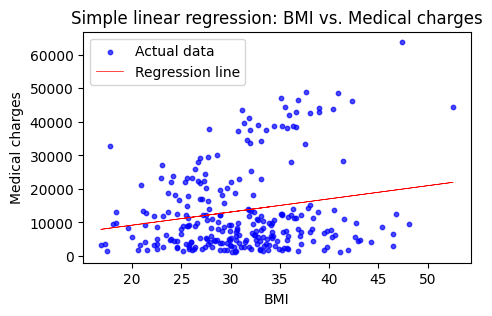

In [51]:
# Copy the 'insurance.csv' dataset into a new DataFrame
df = insurance.copy()

X_2 = df[['bmi']]
y_2 = df['charges']

# Split the data into training and test sets
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_2, y_2, test_size=0.2, random_state=42)

# Create and train the linear regression model
model = LinearRegression()
model.fit(X_train2, y_train2)

# Make predictions
y_pred = model.predict(X_test2)

# Plot the data and the regression line
plt.figure(figsize=(5, 3))
plt.scatter(X_test2, y_test2, color='blue', alpha=0.7, s=10, label='Actual data')
plt.plot(X_test2, y_pred, color='red', linewidth=0.5, label='Regression line')
plt.title('Simple linear regression: BMI vs. Medical charges')
plt.xlabel('BMI')
plt.ylabel('Medical charges')
plt.legend()
plt.show()

In [52]:
# Extract the linear regression coefficients
coefficients = model.coef_
intercept = model.intercept_

# Print the regression line equation
print(f'Regression line equation: y = {coefficients[0]:.2f}X + {intercept:.2f}')

Regression line equation: y = 392.44X + 1353.07


In this example:

1. **Data**: We use the `bmi` feature and the `charges` target variable.
2. **Data splitting**: We split the data into training and test sets.
3. **Model**: We create and train a simple linear regression model.
4. **Predictions**: We make predictions on the test set.
5. **Plot**: We plot the actual data and the fitted regression line.

This plot will allow you to visualize how BMI relates to medical charges and how the fitted regression line represents this relationship.

## Dataset standardization

In [53]:
# Standardize the data in the 'insurance.csv' dataset with the StandardScaler function from scikit-learn
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# Apply standardization to the training and test sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [54]:
# Convert the standardized data to DataFrames to make interpretation easier
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# Display the first rows of the standardized data
X_train_scaled_df.head()

,age,sex,bmi,children,smoker,region_northeast,region_northwest,region_southeast,region_southwest
0,0.472227,-1.024602,-1.756525,0.734336,-0.508747,-0.576631,1.783168,-0.599661,-0.572314
1,0.543313,-1.024602,-1.033082,-0.911192,-0.508747,1.734212,-0.560800,-0.599661,-0.572314
2,0.898745,-1.024602,-0.943687,-0.911192,-0.508747,-0.576631,-0.560800,1.667609,-0.572314
3,-0.025379,-1.024602,0.622393,3.202629,-0.508747,-0.576631,-0.560800,1.667609,-0.572314
4,1.040918,-1.024602,-1.504893,1.557100,-0.508747,-0.576631,1.783168,-0.599661,-0.572314


In [55]:
# Create an instance of the linear regression model
scaled_regression_model = LinearRegression()

# Fit the linear regression model with the standardized data
scaled_regression_model.fit(X_train_scaled_df, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [56]:
# Make predictions on the test set
y_pred_scaled = scaled_regression_model.predict(X_test_scaled_df)

# Calculate the evaluation metrics
mse_scaled = mean_squared_error(y_test, y_pred_scaled)
r2_scaled = r2_score(y_test, y_pred_scaled)
mae_scaled = mean_absolute_error(y_test, y_pred_scaled)
rmse_scaled = np.sqrt(mse_scaled)

# Print the evaluation metrics
print(f'Mean Squared Error (MSE) - Scaled Data: {mse_scaled}')
print(f'Coefficient of Determination (R^2) - Scaled Data: {r2_scaled}')
print(f'Mean Absolute Error (MAE) - Scaled Data: {mae_scaled}')
print(f'Root Mean Squared Error (RMSE) - Scaled Data: {rmse_scaled}')

Mean Squared Error (MSE) - Scaled Data: 33596915.851361476
Coefficient of Determination (R^2) - Scaled Data: 0.7835929767120722
Mean Absolute Error (MAE) - Scaled Data: 4181.194473753652
Root Mean Squared Error (RMSE) - Scaled Data: 5796.284659276274


For ordinary least squares with an intercept, standardizing the predictors preserves the fitted predictions up to numerical precision. StandardScaler changes the scale of `X`, and the model adjusts its coefficients and intercept to compensate.

Scaling allows coefficients to be compared for a one-standard-deviation increase in each predictor. However, these magnitudes do not by themselves establish predictive importance or causality, and correlated predictors can affect their interpretation. For binary indicators, the scaled coefficient no longer represents a direct change from 0 to 1; use the unscaled coefficient for that interpretation.

With all four region indicators and an intercept, coefficients are not unique. Refitting after scaling can select a different allocation among the redundant region columns, even when predictions agree. For the coefficient-to-SHAP comparison below, use the same original fitted model and the same training-data background throughout.

           Variable  Coefficient  Abs_Coefficient
4            smoker  9558.481409      9558.481409
0               age  3614.975415      3614.975415
2               bmi  2036.228123      2036.228123
3          children   516.890247       516.890247
5  region_northeast   199.698058       199.698058
8  region_southwest  -150.167101       150.167101
7  region_southeast   -86.621147        86.621147
6  region_northwest    38.734949        38.734949
1               sex    -9.293101         9.293101


C:\Users\pauls\AppData\Local\Temp\ipykernel_13476\3480408063.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Variable', data=scaled_coef_df, palette='coolwarm')


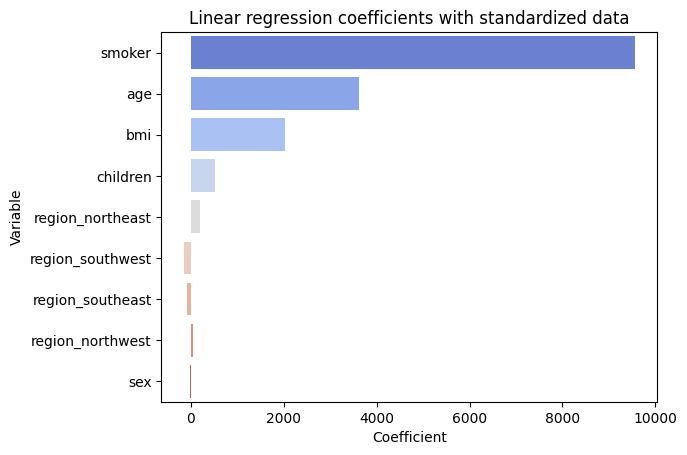

In [57]:
# Plot coefficient magnitudes for the linear regression model with standardized predictors
scaled_coefficients = scaled_regression_model.coef_
scaled_coef_df = pd.DataFrame({'Variable': X.columns, 'Coefficient': scaled_coefficients})
scaled_coef_df['Abs_Coefficient'] = scaled_coef_df['Coefficient'].abs() 
scaled_coef_df = scaled_coef_df.sort_values(by='Abs_Coefficient', ascending=False)
print(scaled_coef_df)

# Plot the coefficients sorted from highest to lowest in a bar chart
sns.barplot(x='Coefficient', y='Variable', data=scaled_coef_df, palette='coolwarm')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.title('Linear regression coefficients with standardized data')
plt.show()

C:\Users\pauls\AppData\Local\Temp\ipykernel_13476\956020363.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Variable', data=coef_df, palette='coolwarm')
C:\Users\pauls\AppData\Local\Temp\ipykernel_13476\956020363.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Variable', data=scaled_coef_df, palette='coolwarm')


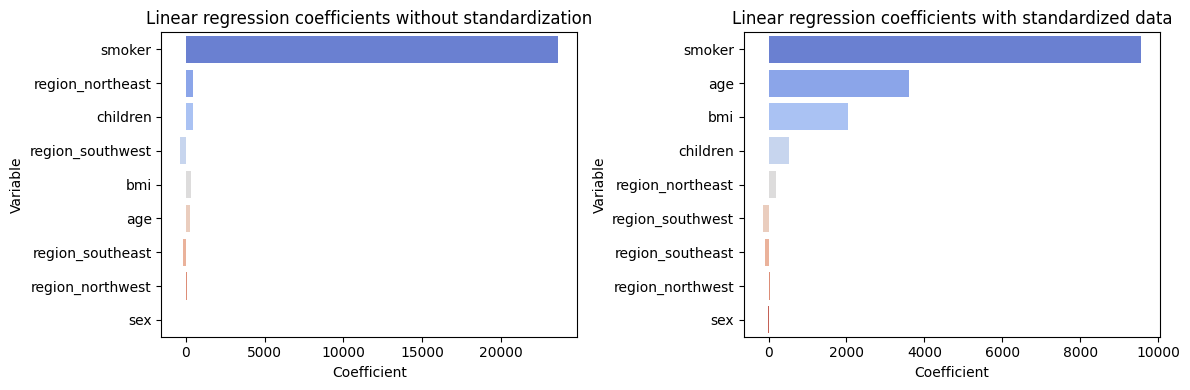

In [58]:
# Plot the linear regression coefficients with unstandardized data (coef_df) and compare them with the linear regression coefficients with standardized data (scaled_coef_df) to compare coefficient magnitudes before and after standardization
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.barplot(x='Coefficient', y='Variable', data=coef_df, palette='coolwarm')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.title('Linear regression coefficients without standardization')
plt.subplot(1, 2, 2)
sns.barplot(x='Coefficient', y='Variable', data=scaled_coef_df, palette='coolwarm')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.title('Linear regression coefficients with standardized data')
plt.tight_layout()
plt.show()


___

### Activity

1. **Find a new dataset:**
   - **Find** a new dataset and **identify** the predictor and target variable(s).

**Dataset:** `wage1` de Wooldridge (*Introductory Econometrics*), tomado de GitHub: repositorio [Rdatasets](https://github.com/vincentarelbundock/Rdatasets) → `csv/wooldridge/wage1.csv`.
Datos de la Current Population Survey (CPS) de EE. UU., **1976**, 526 trabajadores.

**Variable objetivo (y):** `wage` = salario promedio por hora.

**Variables predictoras (X):**
| Variable | Descripción | Tipo |
|---|---|---|
| `educ` | Años de educación | numérica (años) |
| `exper` | Años de experiencia potencial | numérica (años) |
| `tenure` | Años con el empleador actual | numérica (años) |
| `female` | 1 = mujer, 0 = hombre | binaria |
| `married` | 1 = casado/a | binaria |
| `nonwhite` | 1 = no blanco | binaria |
| `numdep` | Número de dependientes | numérica |
| `smsa` | 1 = vive en área metropolitana | binaria |
| `northcen`, `south`, `west` | Región (*northeast* es la categoría omitida) | dummies |

In [59]:
# Paquetes extra: statsmodels (p-values) y openpyxl (Excel)
# %pip install statsmodels openpyxl
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor

# Cargar el dataset directamente desde GitHub
wage = pd.read_csv('https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/wooldridge/wage1.csv')
wage = wage.drop(columns='rownames')   # 'rownames' es solo un índice
print(wage.shape)
print('Valores faltantes:', wage.isna().sum().sum())
wage.head()

(526, 24)
Valores faltantes: 0


,wage,educ,exper,tenure,nonwhite,female,married,numdep,smsa,northcen,...,trcommpu,trade,services,profserv,profocc,clerocc,servocc,lwage,expersq,tenursq
0,3.10,11,2,0,0,1,0,2,1,0,...,0,0,0,0,0,0,0,1.131402,4,0
1,3.24,12,22,2,0,1,1,3,1,0,...,0,0,1,0,0,0,1,1.175573,484,4
2,3.00,11,2,0,0,0,0,2,0,0,...,0,1,0,0,0,0,0,1.098612,4,0
3,6.00,8,44,28,0,0,1,0,1,0,...,0,0,0,0,0,1,0,1.791759,1936,784
4,5.30,12,7,2,0,0,1,1,0,0,...,0,0,0,0,0,0,0,1.667707,49,4


         wage    educ   exper  tenure  female  married  numdep
count  526.00  526.00  526.00  526.00  526.00   526.00  526.00
mean     5.90   12.56   17.02    5.10    0.48     0.61    1.04
std      3.69    2.77   13.57    7.22    0.50     0.49    1.26
min      0.53    0.00    1.00    0.00    0.00     0.00    0.00
25%      3.33   12.00    5.00    0.00    0.00     0.00    0.00
50%      4.65   12.00   13.50    2.00    0.00     1.00    1.00
75%      6.88   14.00   26.00    7.00    1.00     1.00    2.00
max     24.98   18.00   51.00   44.00    1.00     1.00    6.00


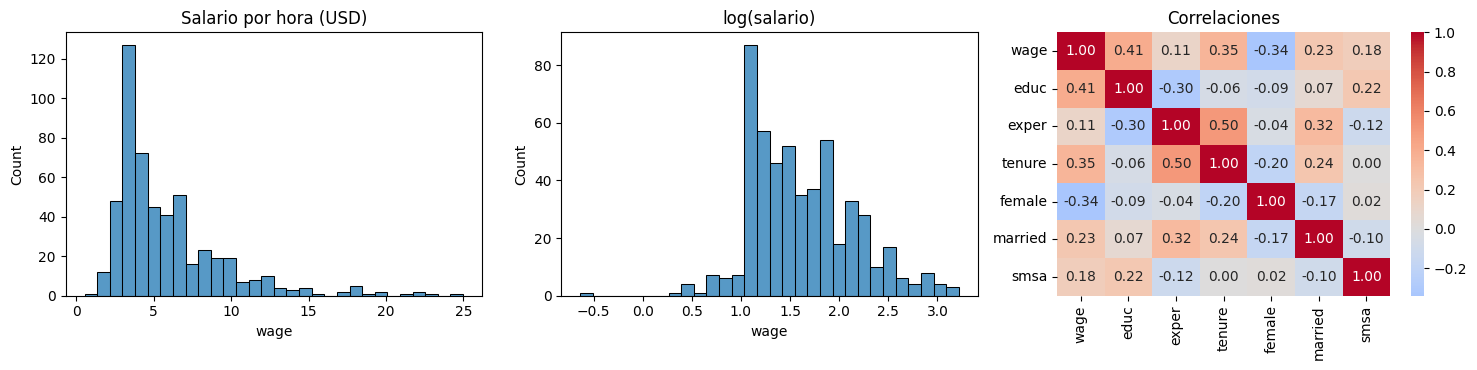

In [60]:
print(wage[['wage', 'educ', 'exper', 'tenure', 'female', 'married', 'numdep']].describe().round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(wage['wage'], bins=30, ax=ax[0]); ax[0].set_title('Salario por hora (USD)')
sns.histplot(np.log(wage['wage']), bins=30, ax=ax[1]); ax[1].set_title('log(salario)')
cols_corr = ['wage', 'educ', 'exper', 'tenure', 'female', 'married', 'smsa']
sns.heatmap(wage[cols_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[2])
ax[2].set_title('Correlaciones')
plt.tight_layout(); plt.show()

**Lectura:** el salario está sesgado a la derecha (pocos ganan mucho); en log se ve más simétrico. `educ` y `tenure` son las más correlacionadas con `wage`; `female` tiene correlación negativa (brecha de género).

In [61]:
# Definir predictores (X) y objetivo (y)
# No uso 'lwage', 'expersq', 'tenursq': son transformaciones (lwage es la propia y en log -> sería trampa)
w_features = ['educ', 'exper', 'tenure', 'female', 'married', 'nonwhite',
              'numdep', 'smsa', 'northcen', 'south', 'west']
w_X = wage[w_features]
w_y = wage['wage']
w_X.head()

,educ,exper,tenure,female,married,nonwhite,numdep,smsa,northcen,south,west
0,11,2,0,1,0,0,2,1,0,0,1
1,12,22,2,1,1,0,3,1,0,0,1
2,11,2,0,0,0,0,2,0,0,0,1
3,8,44,28,0,1,0,0,1,0,0,1
4,12,7,2,0,1,0,1,0,0,0,1



2. **Model Fitting:**
   - **Fit** a linear regression model.
   - **Evaluate** the model's performance (e.g., `RMSE`) based on its unit of measurement.
   - **Analyze** the most significant coefficients for the model.
   - (Optional) Use [`cross_val_score`](https://scikit-learn.org/stable/modules/cross_validation.html) with 5 folds. Calculate the mean RMSE and the standard deviation of all the scores obtained with cross-validation (optional).

In [62]:
w_X_train, w_X_test, w_y_train, w_y_test = train_test_split(w_X, w_y, test_size=0.2, random_state=42)

w_model = LinearRegression()
w_model.fit(w_X_train, w_y_train)

print(f'Intercepto (β0): {w_model.intercept_:.4f}')
pd.DataFrame({'Variable': w_features, 'Coeficiente': w_model.coef_}).round(4)

Intercepto (β0): -2.3742


,Variable,Coeficiente
0,educ,0.5494
1,exper,0.0232
2,tenure,0.1601
3,female,-1.7017
4,married,0.4023
5,nonwhite,0.0723
6,numdep,0.1682
7,smsa,1.0494
8,northcen,-0.5936
9,south,-0.4514


**Evaluación (RMSE y su unidad).** RMSE y MAE están en la misma unidad que y → dólares (de 1976) por hora. Comparamos con un baseline que siempre predice el promedio del entrenamiento.

In [63]:
w_y_pred = w_model.predict(w_X_test)
w_rmse = np.sqrt(mean_squared_error(w_y_test, w_y_pred))

w_base = DummyRegressor(strategy='mean').fit(w_X_train, w_y_train).predict(w_X_test)
print(pd.DataFrame({
    'Modelo': ['Baseline (promedio)', 'Regresión lineal'],
    'RMSE (USD/hora)': [np.sqrt(mean_squared_error(w_y_test, w_base)), w_rmse],
    'MAE (USD/hora)': [mean_absolute_error(w_y_test, w_base), mean_absolute_error(w_y_test, w_y_pred)],
    'R²': [r2_score(w_y_test, w_base), r2_score(w_y_test, w_y_pred)],
}).round(3).to_string(index=False))

print(f'\nSalario promedio en prueba: {w_y_test.mean():.2f} USD/hora')
print(f'RMSE = {w_rmse:.2f} USD/hora → el modelo se equivoca ~{100*w_rmse/w_y_test.mean():.0f}% del salario promedio.')

             Modelo  RMSE (USD/hora)  MAE (USD/hora)     R²
Baseline (promedio)            3.733           2.889 -0.002
   Regresión lineal            2.945           2.014  0.376

Salario promedio en prueba: 6.04 USD/hora
RMSE = 2.94 USD/hora → el modelo se equivoca ~49% del salario promedio.


**Análisis de los coeficientes más significativos.** statsmodels da los mismos coeficientes que scikit-learn, más p-values. "Significativo" = p-value < 0.05 (es poco probable que el efecto real sea cero).

          Coeficiente  p-value  IC95 inf  IC95 sup Significativo
educ           0.5494   0.0000    0.4288    0.6701            Sí
tenure         0.1601   0.0000    0.1118    0.2084            Sí
female        -1.7017   0.0000   -2.2819   -1.1215            Sí
smsa           1.0494   0.0022    0.3812    1.7175            Sí
const         -2.3742   0.0146   -4.2778   -0.4706            Sí
exper          0.0232   0.0907   -0.0037    0.0501            No
northcen      -0.5936   0.1511   -1.4049    0.2178            No
numdep         0.1682   0.1676   -0.0710    0.4073            No
married        0.4023   0.2195   -0.2408    1.0455            No
south         -0.4514   0.2622   -1.2416    0.3389            No
west           0.1870   0.6932   -0.7443    1.1184            No
nonwhite       0.0723   0.8805   -0.8721    1.0167            No


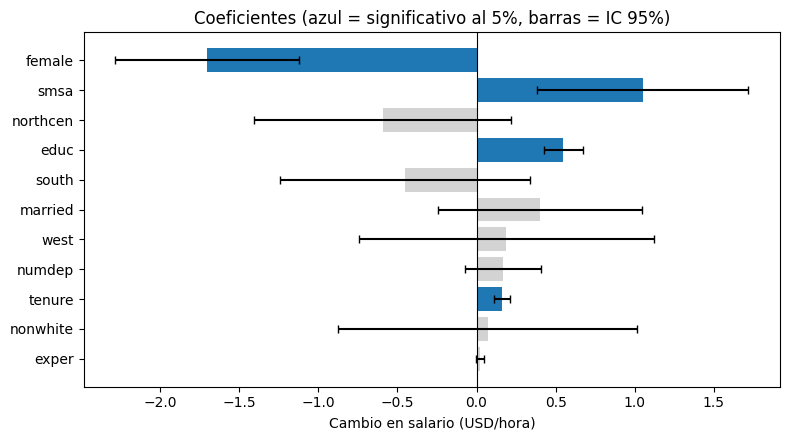

In [64]:
w_ols = sm.OLS(w_y_train, sm.add_constant(w_X_train)).fit()
w_tabla = pd.DataFrame({'Coeficiente': w_ols.params, 'p-value': w_ols.pvalues,
                        'IC95 inf': w_ols.conf_int()[0], 'IC95 sup': w_ols.conf_int()[1]}).round(4)
w_tabla['Significativo'] = np.where(w_tabla['p-value'] < 0.05, 'Sí', 'No')
print(w_tabla.sort_values('p-value'))

w_plot = w_tabla.drop('const').reindex(w_tabla.drop('const')['Coeficiente'].abs().sort_values(ascending=False).index)
plt.figure(figsize=(8, 4.5))
plt.barh(w_plot.index, w_plot['Coeficiente'],
         color=['tab:blue' if s == 'Sí' else 'lightgray' for s in w_plot['Significativo']])
plt.errorbar(w_plot['Coeficiente'], w_plot.index,
             xerr=[w_plot['Coeficiente'] - w_plot['IC95 inf'], w_plot['IC95 sup'] - w_plot['Coeficiente']],
             fmt='none', ecolor='black', capsize=3)
plt.axvline(0, color='black', lw=0.8); plt.gca().invert_yaxis()
plt.xlabel('Cambio en salario (USD/hora)')
plt.title('Coeficientes (azul = significativo al 5%, barras = IC 95%)')
plt.tight_layout(); plt.show()

**Lectura** (manteniendo lo demás constante):
- **`educ`**: cada año extra de educación ≈ +0,55 USD/hora. Es el resultado central de Mincer.
- **`female`**: las mujeres ganan ≈ 1,70 USD/hora menos que hombres con iguales características observadas (brecha de género de 1976).
- **`tenure`**: cada año con el mismo empleador suma salario. **`smsa`**: vivir en zona urbana paga más.
- **`exper`** *no* sale significativa: su efecto es **curvo** (sube y se aplana) y una recta lo capta mal → lo corrijo en el punto 5.
- Como advierte el notebook arriba: binarias (0→1) y numéricas (por 1 año) no se comparan directamente, y esto no prueba causalidad.

**Coeficientes estandarizados: ¿qué variable pesa más?**

**Qué:** reentreno el mismo modelo con `StandardScaler` (media 0, desviación estándar 1 en cada variable).
Así cada coeficiente es el cambio en USD/hora por +1 desviación estándar de la variable, y se pueden comparar entre sí aunque tengan unidades distintas (años vs. 0/1).

          Coef. original (por unidad)  Desv. estándar de la variable  \
educ                            0.549                          2.646   
tenure                          0.160                          7.053   
female                         -1.702                          0.499   
smsa                            1.049                          0.443   
exper                           0.023                         13.554   
northcen                       -0.594                          0.441   
south                          -0.451                          0.481   
numdep                          0.168                          1.245   
married                         0.402                          0.486   
west                            0.187                          0.364   
nonwhite                        0.072                          0.300   

          Coef. estandarizado (por 1 DE)  
educ                               1.454  
tenure                             1.129  
female

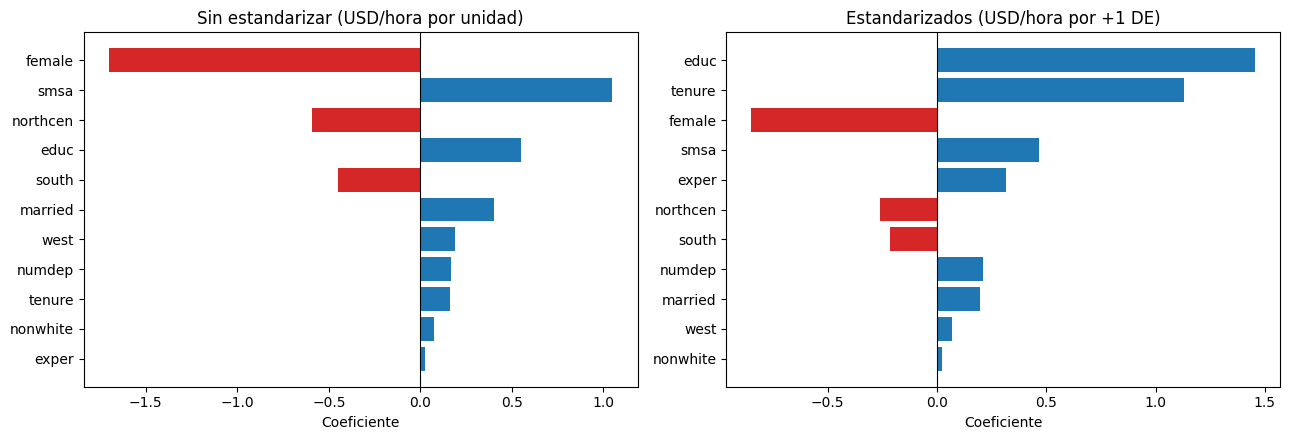

RMSE sin estandarizar: 2.944584 | RMSE estandarizado: 2.944584 USD/hora
¿Mismas predicciones? True


In [65]:
from sklearn.preprocessing import StandardScaler

w_scaler = StandardScaler()
w_X_train_std = w_scaler.fit_transform(w_X_train)   # fit SOLO con entrenamiento
w_X_test_std = w_scaler.transform(w_X_test)         # la prueba solo se transforma

w_model_std = LinearRegression().fit(w_X_train_std, w_y_train)

w_comp_coef = pd.DataFrame({
    'Coef. original (por unidad)': w_model.coef_,
    'Desv. estándar de la variable': w_X_train.std(ddof=0).values,
    'Coef. estandarizado (por 1 DE)': w_model_std.coef_,
}, index=w_features)
w_comp_coef = w_comp_coef.reindex(w_comp_coef['Coef. estandarizado (por 1 DE)'].abs().sort_values(ascending=False).index)
print(w_comp_coef.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
o = w_comp_coef.sort_values('Coef. original (por unidad)', key=abs, ascending=False)
ax[0].barh(o.index, o['Coef. original (por unidad)'], color=np.where(o['Coef. original (por unidad)'] > 0, 'tab:blue', 'tab:red'))
ax[0].set(title='Sin estandarizar (USD/hora por unidad)', xlabel='Coeficiente'); ax[0].invert_yaxis(); ax[0].axvline(0, color='k', lw=.8)
s = w_comp_coef['Coef. estandarizado (por 1 DE)']
ax[1].barh(s.index, s, color=np.where(s > 0, 'tab:blue', 'tab:red'))
ax[1].set(title='Estandarizados (USD/hora por +1 DE)', xlabel='Coeficiente'); ax[1].invert_yaxis(); ax[1].axvline(0, color='k', lw=.8)
plt.tight_layout(); plt.show()

# Comprobación: las predicciones son las mismas con o sin estandarizar
w_rmse_std = np.sqrt(mean_squared_error(w_y_test, w_model_std.predict(w_X_test_std)))
print(f'RMSE sin estandarizar: {w_rmse:.6f} | RMSE estandarizado: {w_rmse_std:.6f} USD/hora')
print('¿Mismas predicciones?', np.allclose(w_model.predict(w_X_test), w_model_std.predict(w_X_test_std)))

**Lectura:**
- Al estandarizar, `educ` pasa a ser la variable más influyente, porque varía mucho entre personas. Le siguen `tenure` y `female`.
- `female` tenía el coeficiente original más grande (−1,70), pero es binaria: su DE es = 0,5, así que su peso estandarizado es menor que el de `educ`.
- El RMSE es idéntico: estandarizar sirve para comparar e interpretar, no para predecir mejor.
- En una dummy, el coeficiente estandarizado ya no significa "pasar de 0 a 1"; para eso se usa el coeficiente original.

**Validación cruzada de 5 folds.** Un solo split puede ser suerte; con 5 folds obtenemos un RMSE promedio y su desviación estándar. scikit-learn devuelve el RMSE en negativo (`neg_root_mean_squared_error`), por eso le cambio el signo.

In [66]:
w_kf = KFold(n_splits=5, shuffle=True, random_state=42)
w_cv = -cross_val_score(LinearRegression(), w_X, w_y, cv=w_kf, scoring='neg_root_mean_squared_error')
print('RMSE por fold (USD/hora):', w_cv.round(3))
print(f'RMSE promedio: {w_cv.mean():.3f} USD/hora | Desv. estándar: {w_cv.std():.3f}')

RMSE por fold (USD/hora): [2.945 3.091 2.589 3.091 3.056]
RMSE promedio: 2.955 USD/hora | Desv. estándar: 0.190


**Residuos.** Si el modelo es adecuado, deberían estar dispersos al azar alrededor de 0. Un abanico que se abre o predicciones negativas indican que conviene modelar `log(wage)` (igual que la nota del notebook sobre `log1p(charges)`).

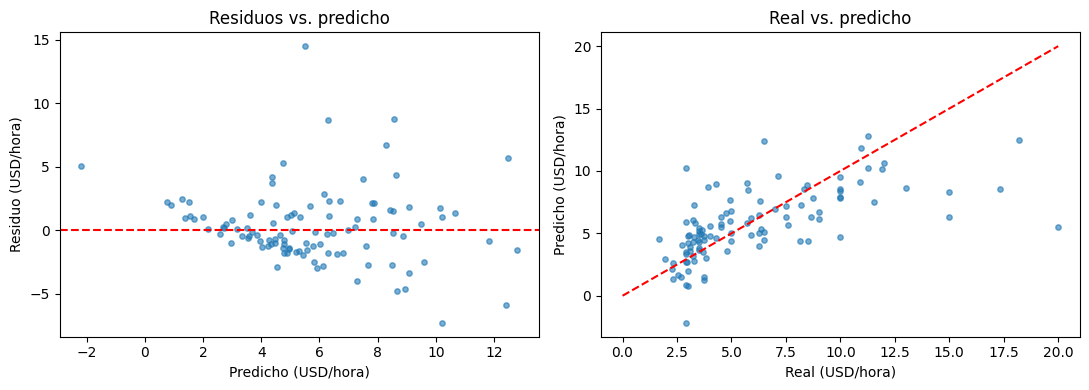

Predicciones negativas: 1


In [67]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(w_y_pred, w_y_test - w_y_pred, alpha=0.6, s=15); ax[0].axhline(0, color='red', ls='--')
ax[0].set(xlabel='Predicho (USD/hora)', ylabel='Residuo (USD/hora)', title='Residuos vs. predicho')
ax[1].scatter(w_y_test, w_y_pred, alpha=0.6, s=15)
lim = [0, max(w_y_test.max(), w_y_pred.max())]; ax[1].plot(lim, lim, 'r--')
ax[1].set(xlabel='Real (USD/hora)', ylabel='Predicho (USD/hora)', title='Real vs. predicho')
plt.tight_layout(); plt.show()
print('Predicciones negativas:', (w_y_pred < 0).sum())

   
3. **Predicting New Records:**
   - Use the fitted model to **predict** the value of `y` for a new record with the `.predict` method.

**Nuevo registro:** mujer, 16 años de educación, 5 de experiencia, 2 en su empleo, casada, 1 dependiente, zona urbana, región sur.

In [68]:
w_nuevo = pd.DataFrame({
    'educ': [16], 'exper': [5], 'tenure': [2],
    'female': [1], 'married': [1], 'nonwhite': [0], 'numdep': [1],
    'smsa': [1], 'northcen': [0], 'south': [1], 'west': [0],
})[w_features]

w_pred_nuevo = w_model.predict(w_nuevo)[0]
print(f'Salario estimado con .predict: {w_pred_nuevo:.4f} USD/hora')


Salario estimado con .predict: 6.3198 USD/hora


In [69]:
w_detalle = pd.DataFrame({'Variable': w_features, 'Coeficiente (β)': w_model.coef_, 'Valor (x)': w_nuevo.iloc[0].values})
w_detalle['β · x'] = w_detalle['Coeficiente (β)'] * w_detalle['Valor (x)']
print(w_detalle.round(4).to_string(index=False))
print(f'\nIntercepto + Σ(β·x) = {w_model.intercept_ + w_detalle["β · x"].sum():.4f}  |  .predict = {w_pred_nuevo:.4f}')

Variable  Coeficiente (β)  Valor (x)   β · x
    educ           0.5494         16  8.7910
   exper           0.0232          5  0.1160
  tenure           0.1601          2  0.3203
  female          -1.7017          1 -1.7017
 married           0.4023          1  0.4023
nonwhite           0.0723          0  0.0000
  numdep           0.1682          1  0.1682
    smsa           1.0494          1  1.0494
northcen          -0.5936          0 -0.0000
   south          -0.4514          1 -0.4514
    west           0.1870          0  0.0000

Intercepto + Σ(β·x) = 6.3198  |  .predict = 6.3198


4. **Predicting New Records:**
   - Use the fitted model to **predict** the value of `y` for the previous record in an Excel spreadsheet.

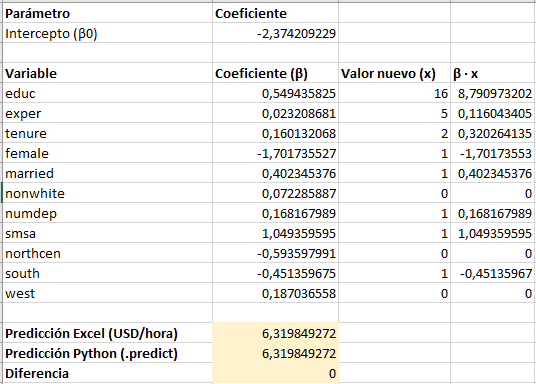

Paste the screenshot here..

**Comparación:** Excel y Python dan el mismo valor (= 6,32 USD/hora). Un modelo lineal entrenado es solo una ecuación.

5. **Possible improvements:**
   - Suggest an improvement proposal to optimize **model performance**.

Para mejorar el modelo partimos de lo que vimos en los residuos. Primero, en lugar de predecir el salario directamente, predecimos su logaritmo, `log(wage)`. El salario tiene pocos valores muy altos que jalan el modelo, y con el logaritmo eso se suaviza: los errores dejan de abrirse en forma de abanico y ya no salen salarios negativos. Segundo, agregamos la experiencia y la antigüedad al cuadrado (`expersq`, `tenursq`), porque los primeros años de trabajo suben el salario mucho más que los últimos, y una línea recta no capta esa curva. Tercero, incluimos la combinación de ser mujer y estar casada (`female × married`), ya que la diferencia de salario entre hombres y mujeres puede no ser la misma para personas solteras y casadas. Por último, sumamos variables de ocupación e industria, que dan información sobre el tipo de trabajo que el modelo base no tenía.

Para comparar los modelos de forma justa, todos se evalúan con la misma validación cruzada de 5 folds y el error siempre se mide en dólares por hora. En el caso del modelo con logaritmo, usamos `TransformedTargetRegressor`, que entrena con `log(wage)` pero al predecir devuelve el resultado en dólares (aplica `exp`), así su RMSE se puede comparar directamente con el de los demás.

                                            Modelo  N° vars  RMSE CV (USD/h)  Desv. RMSE  MAE CV (USD/h)
                                   A. Base (nivel)       11            2.955       0.190           2.096
                                  B. + cuadráticos       13            2.879       0.194           2.062
                        C. log(wage) + cuadráticos       13            2.807       0.310           1.849
D. log + cuad. + interacción + ocupación/industria       23            2.590       0.283           1.685


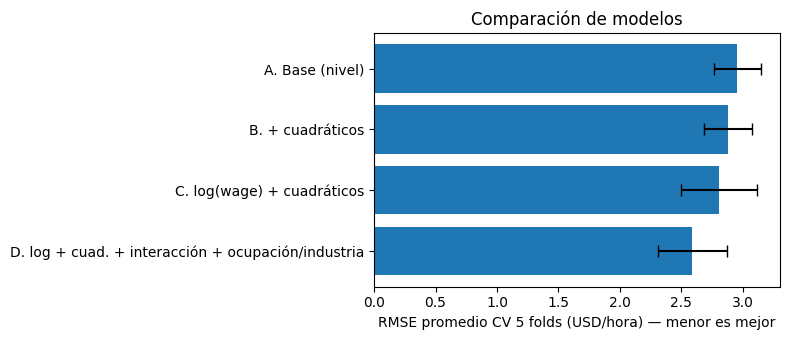

In [70]:
from sklearn.compose import TransformedTargetRegressor

wage['female_married'] = wage['female'] * wage['married']
w_ocup_ind = ['profocc', 'clerocc', 'servocc', 'construc', 'ndurman', 'trcommpu', 'trade', 'services', 'profserv']
w_f_cuad = w_features + ['expersq', 'tenursq']
w_f_full = w_f_cuad + ['female_married'] + w_ocup_ind

w_lin = LinearRegression()
w_loglin = TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp)

w_modelos = {
    'A. Base (nivel)': (w_lin, w_features),
    'B. + cuadráticos': (w_lin, w_f_cuad),
    'C. log(wage) + cuadráticos': (w_loglin, w_f_cuad),
    'D. log + cuad. + interacción + ocupación/industria': (w_loglin, w_f_full),
}
filas = []
for nombre, (est, cols) in w_modelos.items():
    s = -cross_val_score(est, wage[cols], w_y, cv=w_kf, scoring='neg_root_mean_squared_error')
    m = -cross_val_score(est, wage[cols], w_y, cv=w_kf, scoring='neg_mean_absolute_error')
    filas.append({'Modelo': nombre, 'N° vars': len(cols), 'RMSE CV (USD/h)': s.mean(),
                  'Desv. RMSE': s.std(), 'MAE CV (USD/h)': m.mean()})
w_comp = pd.DataFrame(filas).round(3)
print(w_comp.to_string(index=False))

plt.figure(figsize=(8, 3.5))
plt.barh(w_comp['Modelo'], w_comp['RMSE CV (USD/h)'], xerr=w_comp['Desv. RMSE'], capsize=4)
plt.gca().invert_yaxis(); plt.xlabel('RMSE promedio CV 5 folds (USD/hora) — menor es mejor')
plt.title('Comparación de modelos'); plt.tight_layout(); plt.show()

In [71]:
w_ols_log = sm.OLS(np.log(w_y_train), sm.add_constant(wage.loc[w_X_train.index, w_f_full])).fit()
t = pd.DataFrame({'β': w_ols_log.params, 'p-value': w_ols_log.pvalues})
t['Efecto aprox. (%)'] = 100 * (np.exp(t['β']) - 1)
print(t.drop('const').query('`p-value` < 0.05').sort_values('p-value').round(4))

b = w_ols_log.params
print(f"\nCada año extra de educación ≈ +{100*(np.exp(b['educ'])-1):.1f}% de salario.")
print(f"Mujer soltera vs. hombre soltero ≈ {100*(np.exp(b['female'])-1):.1f}%.")
print(f"Mujer casada vs. hombre casado ≈ {100*(np.exp(b['female']+b['female_married'])-1):.1f}%.")
print(f"La experiencia deja de subir el salario cerca de los {-b['exper']/(2*b['expersq']):.0f} años.")

                     β  p-value  Efecto aprox. (%)
educ            0.0484   0.0000             4.9593
trade          -0.3003   0.0000           -25.9373
exper           0.0259   0.0000             2.6249
expersq        -0.0005   0.0000            -0.0540
services       -0.2951   0.0002           -25.5563
profocc         0.1944   0.0003            21.4582
smsa            0.1585   0.0003            17.1766
female_married -0.2669   0.0007           -23.4253
married         0.1987   0.0009            21.9864
tenure          0.0199   0.0056             2.0147

Cada año extra de educación ≈ +5.0% de salario.
Mujer soltera vs. hombre soltero ≈ -10.5%.
Mujer casada vs. hombre casado ≈ -31.5%.
La experiencia deja de subir el salario cerca de los 24 años.


In [72]:
# Mismo registro del punto 3 con el modelo mejorado (hay que crear las mismas columnas nuevas)
w_nuevo_full = w_nuevo.copy()
w_nuevo_full['expersq'] = w_nuevo_full['exper'] ** 2
w_nuevo_full['tenursq'] = w_nuevo_full['tenure'] ** 2
w_nuevo_full['female_married'] = w_nuevo_full['female'] * w_nuevo_full['married']
for c in w_ocup_ind: w_nuevo_full[c] = 0
w_nuevo_full['profocc'] = 1; w_nuevo_full['profserv'] = 1   # supuesto: profesional en servicios profesionales
w_nuevo_full = w_nuevo_full[w_f_full]

w_best = TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp)
w_best.fit(wage.loc[w_X_train.index, w_f_full], w_y_train)
print(f'Modelo base:     {w_pred_nuevo:.2f} USD/hora')
print(f'Modelo mejorado: {w_best.predict(w_nuevo_full)[0]:.2f} USD/hora')

Modelo base:     6.32 USD/hora
Modelo mejorado: 5.58 USD/hora



### **Conclusions:**
Through this analysis, we have learned to use linear regression to predict the medical charges of an insurance company's customers. This technique allows us to better understand the relationships between different variables and make informed predictions that can guide medical insurance business strategies.

# **Grading Rubric**

1. Dataset source and description of variables: **1pts**
2. Fitting the linear regressor (simple or multiple): **1pts**
3. Calculating the *RMSE* metric and identifying its unit of measurement: **1pts** 
4. Predicting a **new example** using the `.predict` method in a Jupyter Notebook or `.py` script: **1pts**
5. Predicting the **new example** from the previous step using an Excel spreadsheet and comparing results: **3pts**
6. Proposing improvements to optimize the metrics: **3pts**

## Reproduce linear SHAP contributions using regression coefficients

A coefficient is a slope, not an individual contribution. For the independent-feature SHAP explanation of a linear model, we can calculate the same contributions directly:

$$\mu_j=\operatorname{mean}(X_{\mathrm{train},j}),\qquad
\phi_{ij}=\beta_j(x_{ij}-\mu_j).$$

The reference prediction is:

$$\text{baseline}=\beta_0+\sum_j\beta_j\mu_j.$$

Adding the contributions reconstructs the prediction:

$$\text{baseline}+\sum_j\phi_{ij}
=\beta_0+\sum_j\beta_jx_{ij}=\hat y_i.$$

**Compare contributions with contributions, not coefficients with contributions.** A negative coefficient can produce a positive contribution when the feature is below its background mean. For a global comparison, average the absolute contributions: $\operatorname{mean}_i|\phi_{ij}|$. These magnitudes are nonnegative, just like the SHAP bar plot.

The next cell does not use the SHAP package. It explains the first test customer and creates the global contribution ranking using only the original regression coefficients and the training means.

                   Coefficient  Value minus training mean  \
age                 256.975706                   5.642991   
sex                 -18.591692                  -0.512150   
bmi                 337.092552                  -5.385397   
children            425.278784                   0.892523   
smoker            23651.128856                  -0.205607   
region_northeast    459.585244                   0.750467   
region_northwest     88.907918                  -0.239252   
region_southeast   -198.279052                  -0.264486   
region_southwest   -350.214110                  -0.246729   

                  Manual contribution ($)  
age                           1450.111506  
sex                              9.521726  
bmi                          -1815.377284  
children                       379.571251  
smoker                       -4862.848924  
region_northeast               344.903693  
region_northwest               -21.271427  
region_southeast                52.44

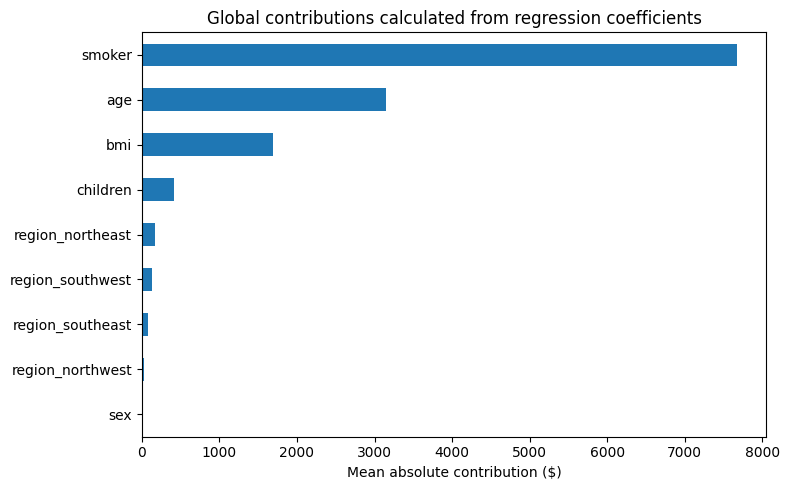

In [74]:
feature_means = X_train.mean()
manual_contributions = (X_test - feature_means) * regression_model.coef_
manual_baseline = regression_model.intercept_ + np.dot(feature_means, regression_model.coef_)

# Local contributions: preserve the signs for the first test customer.
local_comparison = pd.DataFrame({
    'Coefficient': regression_model.coef_,
    'Value minus training mean': X_test.iloc[0] - feature_means,
    'Manual contribution ($)': manual_contributions.iloc[0]
}, index=X_train.columns)
print(local_comparison)
print(f'Baseline + contributions: ${manual_baseline + manual_contributions.iloc[0].sum():,.2f}')
print(f'Model prediction: ${regression_model.predict(X_test.iloc[[0]])[0]:,.2f}')

# Global contributions: the same quantity displayed by the SHAP bar plot.
manual_contributions.abs().mean().sort_values().plot.barh(figsize=(8, 5))
plt.xlabel('Mean absolute contribution ($)')
plt.title('Global contributions calculated from regression coefficients')
plt.tight_layout()
plt.show()

## Explain predictions with SHAP

Run the preceding training cells first: this section uses `regression_model`, `X_train`, and `X_test`. Install SHAP with the next cell, then run the explanation cells.

SHAP attributes the difference between a reference prediction and an individual prediction to the input features. We explain the original multiple-regression model, `regression_model`, using training data as the reference. We will compare SHAP with the manual contributions calculated immediately above.

For a linear model with independent-feature masking, a feature's contribution is $\phi_j=\beta_j(x_j-\mu_j)$, where $\mu_j$ is its mean in the background data. The baseline plus all contributions equals the prediction. This connects coefficient size to how far a customer's feature value is from the reference.

- **Bar plot:** average absolute contributions across test customers, in dollars. This helps compare `age`, `bmi`, and the other inputs on a common scale; it does not show direction.
- **Waterfall plot:** contributions for the first test customer. Red increases the prediction above the baseline; blue decreases it.

This simple explanation treats features independently and does not model their correlations. Region indicators are explained separately, although they belong to one categorical feature. Interpret these plots as explanations of this fitted model, not causal effects or proof that a feature should be removed.

References: [LinearExplainer](https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html), [bar plot](https://shap.readthedocs.io/en/latest/generated/shap.plots.bar.html), and [waterfall plot](https://shap.readthedocs.io/en/stable/example_notebooks/api_examples/plots/waterfall.html).

Because all four region indicators are included with an intercept, individual regional attributions depend on the coefficient representation selected by the solver. Independent masking also ignores the constraint that exactly one region is active. The equality demonstrated here holds for this specific fitted model and background; it does not make the individual regional attributions uniquely meaningful.

In [73]:
%pip install shap

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 860.2 kB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 832.8 kB/s  0:00:01
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   ------------- -------------------------- 1/3 [cloudpickle]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- --------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


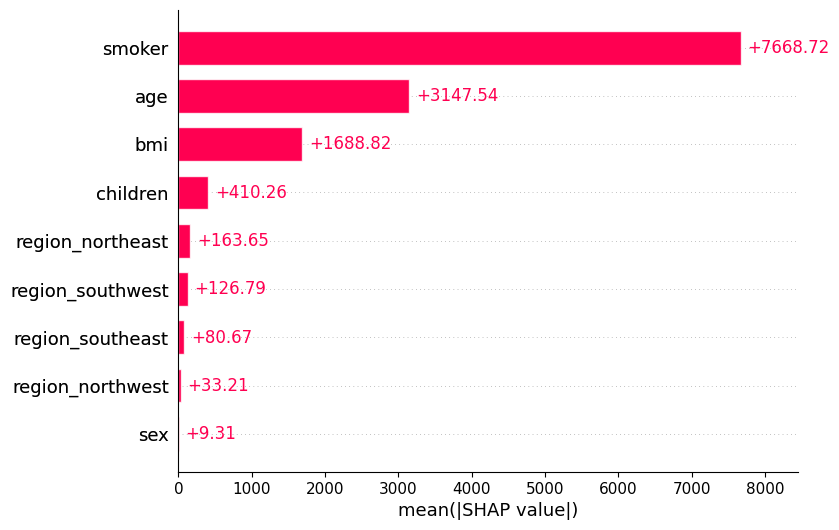

In [75]:
import shap

# Explain the original multiple-regression model in dollars.
background = shap.maskers.Independent(X_train, max_samples=len(X_train))
explainer = shap.LinearExplainer(regression_model, background)
shap_values = explainer(X_test)

# Global view: average absolute contribution across test customers.
shap.plots.bar(shap_values)

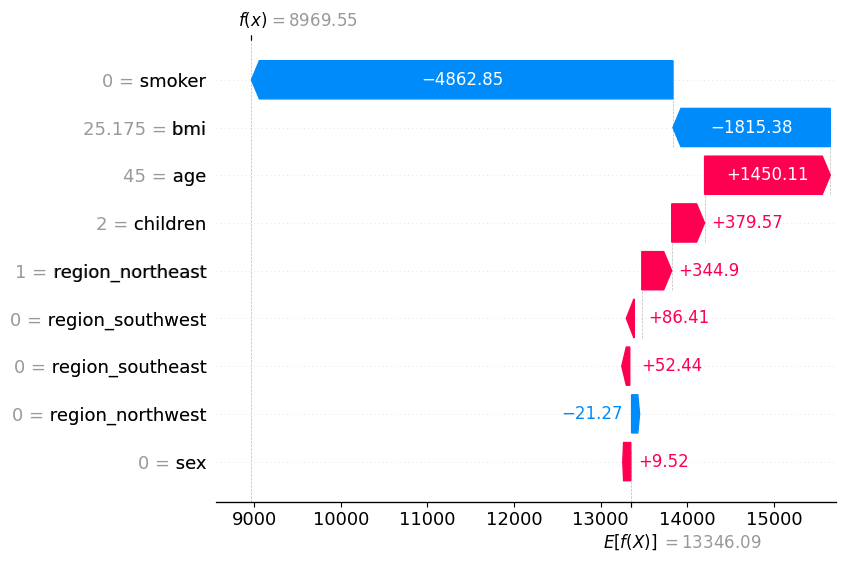

Baseline prediction: $13,346.09
Baseline + contributions: $8,969.55
Model prediction: $8,969.55


In [76]:
# Local view: explain the first test customer's prediction.
shap.plots.waterfall(shap_values[0])

print(f'Baseline prediction: ${shap_values.base_values[0]:,.2f}')
print(f'Baseline + contributions: ${shap_values.base_values[0] + shap_values.values[0].sum():,.2f}')
print(f'Model prediction: ${regression_model.predict(X_test.iloc[[0]])[0]:,.2f}')

### Verify that the manual contributions match SHAP

Both methods use the same original model, all training rows as the background, and independent-feature masking. The table compares signed contributions for the same test customer. The checks compare all test customers and verify that the contributions reconstruct the model predictions.

In [77]:
local_comparison['SHAP contribution ($)'] = shap_values.values[0]
print(local_comparison)

np.testing.assert_allclose(manual_contributions.to_numpy(), shap_values.values, rtol=1e-7, atol=1e-6)
np.testing.assert_allclose(manual_baseline, shap_values.base_values, rtol=1e-7, atol=1e-6)
np.testing.assert_allclose(manual_baseline + manual_contributions.sum(axis=1),
                           regression_model.predict(X_test), rtol=1e-7, atol=1e-6)
print('Manual contributions match SHAP and reconstruct the model predictions.')

                   Coefficient  Value minus training mean  \
age                 256.975706                   5.642991   
sex                 -18.591692                  -0.512150   
bmi                 337.092552                  -5.385397   
children            425.278784                   0.892523   
smoker            23651.128856                  -0.205607   
region_northeast    459.585244                   0.750467   
region_northwest     88.907918                  -0.239252   
region_southeast   -198.279052                  -0.264486   
region_southwest   -350.214110                  -0.246729   

                  Manual contribution ($)  SHAP contribution ($)  
age                           1450.111506            1450.111506  
sex                              9.521726               9.521726  
bmi                          -1815.377284           -1815.377284  
children                       379.571251             379.571251  
smoker                       -4862.848924           -4